In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset

You will use the dataset for final exam score prediction below in this exercise. The dataset contains 10 examples with three features (quiz, lab and midterm) shown in a table below.

| **Quiz (25)** | **Lab (15)** | **Midterm (25)** | **Final (35)** |
|:--------:|:-------:|:-----------:|:---------:|
|   18.0   |   14.7  |     15.0    |    18.4   |
|    4.5   |   14.6  |     3.4     |    3.3    |
|    8.7   |   14.1  |     4.1     |    10.6   |
|    3.5   |   15.0  |     12.8    |    5.5    |
|   12.0   |   13.7  |     13.4    |    7.4    |
|   20.0   |   14.4  |     18.1    |    8.5    |
|    8.0   |   6.4   |     8.4     |    7.9    |
|    5.5   |   14.8  |     4.4     |    5.7    |
|    2.6   |   6.5   |     1.3     |    0.9    |
|    9.3   |   13.3  |     5.3     |    7.8    |

You will build a linear regression model using these values so you can then predict the final exam score for other students. For example, a student with quiz=17.4, lab=14.3, and midterm=10.9 scores.

In [2]:
data = np.array([
    [18. , 14.7, 15. , 18.4],
    [ 4.5, 14.6,  3.4,  3.3],
    [ 8.7, 14.1,  4.1, 10.6],
    [ 3.5, 15. , 12.8,  5.5],
    [12. , 13.7, 13.4,  7.4],
    [20. , 14.4, 18.1,  8.5],
    [ 8. ,  6.4,  8.4,  7.9],
    [ 5.5, 14.8,  4.4,  5.7],
    [ 2.6,  6.5,  1.3,  0.9],
    [ 9.3, 13.3,  5.3,  7.8],
    [ 9.2, 14.6, 20.3, 14.4],
    [17.4, 14.3, 10.9, 11.2],
    [14.4, 15. , 19.1, 15.1],
    [ 5.4, 13.2,  1.9,  2. ],
    [ 0.5,  7.2,  0. ,  1.8],
    [ 6.3, 12.5,  1.6,  4.6],
    [ 6.2, 13.2,  5.6,  5.9],
    [18.4, 14.9, 17.5, 16.6],
    [19.4, 15. , 20.6, 17.7],
    [22.7, 14.1, 15.9, 26. ],
    [24.1, 15. , 25. , 33.3],
    [ 8.6, 12.8, 11.6,  5.3],
    [17.9, 14.8, 12.5, 20.1],
    [13.8, 15. ,  8.4,  9.4],
    [ 5.2, 14.3,  1.6,  0.9]
])
score_df = pd.DataFrame(data, columns=['Quiz', 'Lab', 'Midterm', 'Final'])
score_df

,Quiz,Lab,Midterm,Final
0,18.0,14.7,15.0,18.4
1,4.5,14.6,3.4,3.3
2,8.7,14.1,4.1,10.6
3,3.5,15.0,12.8,5.5
4,12.0,13.7,13.4,7.4
5,20.0,14.4,18.1,8.5
6,8.0,6.4,8.4,7.9
7,5.5,14.8,4.4,5.7
8,2.6,6.5,1.3,0.9
9,9.3,13.3,5.3,7.8


# Linear Regression: Predict the final exam score

Extract `X` and `y`:
* `X`: Quiz, Lab and Midterm
* `y`: Final

Note: Once you select the columns, please use `.values` to extract the data as numpy array.

In [3]:
X = score_df[['Quiz', 'Lab', 'Midterm']].values
y = score_df['Final'].values

In [4]:
print(X)
print(y)

# Expected output:
# [[18.  14.7 15. ]
#  [ 4.5 14.6  3.4]
#  [ 8.7 14.1  4.1]
#  [ 3.5 15.  12.8]
#  [12.  13.7 13.4]
#  [20.  14.4 18.1]
#  [ 8.   6.4  8.4]
#  [ 5.5 14.8  4.4]
#  [ 2.6  6.5  1.3]
#  [ 9.3 13.3  5.3]
#  [ 9.2 14.6 20.3]
#  [17.4 14.3 10.9]
#  [14.4 15.  19.1]
#  [ 5.4 13.2  1.9]
#  [ 0.5  7.2  0. ]
#  [ 6.3 12.5  1.6]
#  [ 6.2 13.2  5.6]
#  [18.4 14.9 17.5]
#  [19.4 15.  20.6]
#  [22.7 14.1 15.9]
#  [24.1 15.  25. ]
#  [ 8.6 12.8 11.6]
#  [17.9 14.8 12.5]
#  [13.8 15.   8.4]
#  [ 5.2 14.3  1.6]]
# [18.4  3.3 10.6  5.5  7.4  8.5  7.9  5.7  0.9  7.8 14.4 11.2 15.1  2.
#   1.8  4.6  5.9 16.6 17.7 26.  33.3  5.3 20.1  9.4  0.9]

[[18.  14.7 15. ]
 [ 4.5 14.6  3.4]
 [ 8.7 14.1  4.1]
 [ 3.5 15.  12.8]
 [12.  13.7 13.4]
 [20.  14.4 18.1]
 [ 8.   6.4  8.4]
 [ 5.5 14.8  4.4]
 [ 2.6  6.5  1.3]
 [ 9.3 13.3  5.3]
 [ 9.2 14.6 20.3]
 [17.4 14.3 10.9]
 [14.4 15.  19.1]
 [ 5.4 13.2  1.9]
 [ 0.5  7.2  0. ]
 [ 6.3 12.5  1.6]
 [ 6.2 13.2  5.6]
 [18.4 14.9 17.5]
 [19.4 15.  20.6]
 [22.7 14.1 15.9]
 [24.1 15.  25. ]
 [ 8.6 12.8 11.6]
 [17.9 14.8 12.5]
 [13.8 15.   8.4]
 [ 5.2 14.3  1.6]]
[18.4  3.3 10.6  5.5  7.4  8.5  7.9  5.7  0.9  7.8 14.4 11.2 15.1  2.
  1.8  4.6  5.9 16.6 17.7 26.  33.3  5.3 20.1  9.4  0.9]


In [5]:
# Create a linear regression model
from sklearn.linear_model import (
    LinearRegression
)

model = LinearRegression()  # Create a model
model = model.fit(X, y)  # .fit() is a function to train a model based on X and y

In [6]:
# Make prediction
y_preds = model.predict(X)
print(y_preds)

[17.0103827   2.69044341  6.25986665  4.94684868 11.94037986 19.62733565
  8.14371021  3.7719976   1.5889596   7.22740078 11.90644968 15.24840605
 15.51214916  3.0838538  -0.56730581  3.77914007  4.92308503 18.11716775
 19.90192942 21.04841454 25.01075942  8.81785827 16.0978072  11.52877599
  2.68418429]


In [7]:
# Get the adjusted model parameters: W and b
print(model.coef_, model.intercept_)

[ 0.77938382 -0.13201865  0.3285741 ] -0.0064634437406922984


What is the most important feature? Why?

ANSWER: The most important feature is the **Quiz** score because it has the largest absolute coefficient value ($|W_{\text{Quiz}}| \approx 0.7794$) among all features ($W_{\text{Lab}} \approx -0.1320$, $W_{\text{Midterm}} \approx 0.3286$). In a linear regression model, a larger coefficient magnitude indicates a greater influence on the predicted final exam score.


In [8]:
f_imp_idx = 0
print(f_imp_idx)


0


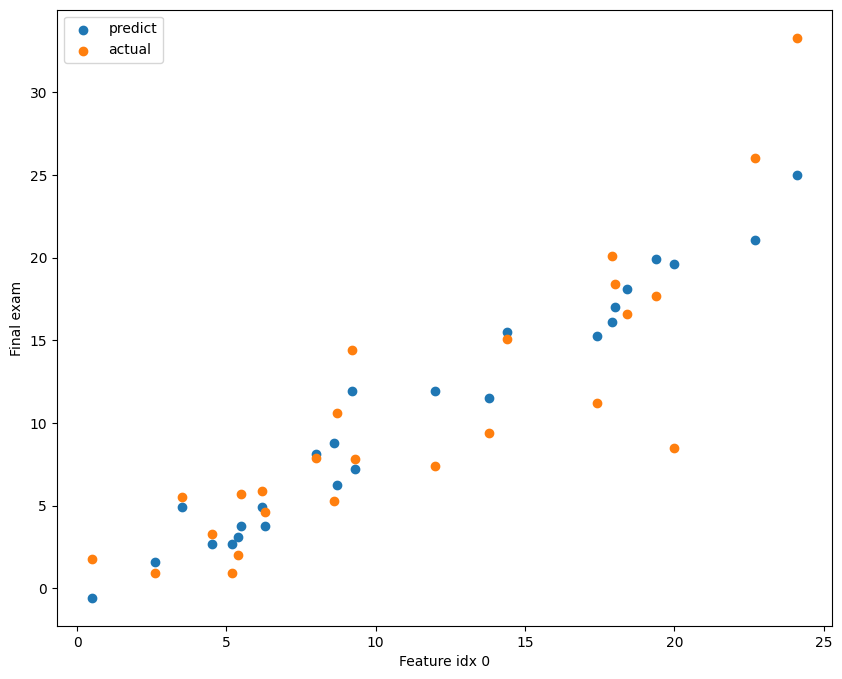

In [9]:
# Visualize the most important feature with the final exam score on the dataset
fig, ax = plt.subplots(figsize=(10,8))
ax.scatter(X[:,f_imp_idx], y_preds, label='predict')
ax.scatter(X[:,f_imp_idx], y, label='actual')
ax.set_xlabel(f'Feature idx {f_imp_idx}')
ax.set_ylabel('Final exam')
plt.legend()
plt.show(); plt.close('all');

In [10]:
# Create a new student with quiz=12, lab=12 and midterm=12
X_new = np.array([[12, 12, 12]])

In [11]:
# Predict the final exam score using the trained linear regression above
y_hat = model.predict(X_new)
print(y_hat)

[11.70480782]


In [12]:
# Performance metrics
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    root_mean_squared_error,
    mean_absolute_error
)

In [13]:
mse = mean_squared_error(y, y_preds)
rmse = root_mean_squared_error(y, y_preds)
mae = mean_absolute_error(y, y_preds)
r2 = r2_score(y, y_preds)

print(f'Mean squared error: {mse}')  # lower is better
print(f'Root mean squared error: {rmse}')  # lower is better
print(f'Mean absolute error: {mae}')  # lower is better
print(f'R2: {r2}')  # higher is better

Mean squared error: 13.525171031597619
Root mean squared error: 3.677658362545061
Mean absolute error: 2.6635768048571085
R2: 0.7865893019682699


TODO:
1. Create a new model, `model2` using only the most important feature
1. According to the performance metrics, which ones (`model` vs. `model2`) is better?

ANSWER: The original `model` (using all features: Quiz, Lab, and Midterm) is better than `model2` (using only Quiz).

Comparing the performance metrics:
- **`model` (All features)**: MSE $\approx 13.5252$, RMSE $\approx 3.6777$, MAE $\approx 2.6636$, $R^2 \approx 0.7866$
- **`model2` (Quiz only)**: MSE $\approx 15.4262$, RMSE $\approx 3.9276$, MAE $\approx 2.8878$, $R^2 \approx 0.7566$

`model` achieves lower error across all metrics (lower MSE, RMSE, and MAE) and a higher $R^2$ score, demonstrating that including Lab and Midterm scores captures additional variance in the final exam score that Quiz alone cannot explain.


In [14]:
# Create a new model, model2 using only the most important feature (Quiz)
X_imp = X[:, [f_imp_idx]]
model2 = LinearRegression()
model2 = model2.fit(X_imp, y)

# Make prediction and evaluate metrics
y_preds2 = model2.predict(X_imp)

mse2 = mean_squared_error(y, y_preds2)
rmse2 = root_mean_squared_error(y, y_preds2)
mae2 = mean_absolute_error(y, y_preds2)
r2_2 = r2_score(y, y_preds2)

print(f'Mean squared error: {mse2}')
print(f'Root mean squared error: {rmse2}')
print(f'Mean absolute error: {mae2}')
print(f'R2: {r2_2}')


Mean squared error: 15.426240583405615
Root mean squared error: 3.927625310974255
Mean absolute error: 2.88775184561511
R2: 0.7565927437650211


# Logistic Regression: Predict Pass/Fail Students

You first need to compute the `Total` score: `Quiz + Lab + Midterm + Final`.


In [15]:
score_df['Total'] = score_df[['Quiz', 'Lab', 'Midterm', 'Final']].sum(axis=1)


Next create a new column, named `Pass` where:

*   `1`: `(50, 100]` (i.e., pass)
*   `0`: `(0, 50]` (i.e., fail)

Hint: you may find `apply` function helpful to convert from the total score to `1`/`0`.

In [16]:
score_df['Pass'] = score_df['Total'].apply(lambda x: 1 if x > 50 else 0)


Extract `X` and `y`:
* `X`: Quiz, Lab and Midterm
* `y`: Pass

Note: Once you select the columns, please use `.values` to extract the data as numpy array.

In [17]:
X = score_df[['Quiz', 'Lab', 'Midterm']].values
y = score_df['Pass'].values


In [18]:
print(X)
print(y)

# Expected output:
# [[18.  14.7 15. ]
#  [ 4.5 14.6  3.4]
#  [ 8.7 14.1  4.1]
#  [ 3.5 15.  12.8]
#  [12.  13.7 13.4]
#  [20.  14.4 18.1]
#  [ 8.   6.4  8.4]
#  [ 5.5 14.8  4.4]
#  [ 2.6  6.5  1.3]
#  [ 9.3 13.3  5.3]
#  [ 9.2 14.6 20.3]
#  [17.4 14.3 10.9]
#  [14.4 15.  19.1]
#  [ 5.4 13.2  1.9]
#  [ 0.5  7.2  0. ]
#  [ 6.3 12.5  1.6]
#  [ 6.2 13.2  5.6]
#  [18.4 14.9 17.5]
#  [19.4 15.  20.6]
#  [22.7 14.1 15.9]
#  [24.1 15.  25. ]
#  [ 8.6 12.8 11.6]
#  [17.9 14.8 12.5]
#  [13.8 15.   8.4]
#  [ 5.2 14.3  1.6]]
# [1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 0 1 0 0]

[[18.  14.7 15. ]
 [ 4.5 14.6  3.4]
 [ 8.7 14.1  4.1]
 [ 3.5 15.  12.8]
 [12.  13.7 13.4]
 [20.  14.4 18.1]
 [ 8.   6.4  8.4]
 [ 5.5 14.8  4.4]
 [ 2.6  6.5  1.3]
 [ 9.3 13.3  5.3]
 [ 9.2 14.6 20.3]
 [17.4 14.3 10.9]
 [14.4 15.  19.1]
 [ 5.4 13.2  1.9]
 [ 0.5  7.2  0. ]
 [ 6.3 12.5  1.6]
 [ 6.2 13.2  5.6]
 [18.4 14.9 17.5]
 [19.4 15.  20.6]
 [22.7 14.1 15.9]
 [24.1 15.  25. ]
 [ 8.6 12.8 11.6]
 [17.9 14.8 12.5]
 [13.8 15.   8.4]
 [ 5.2 14.3  1.6]]
[1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 0 1 0 0]


Create and train a logistic regression model.

In [19]:
from sklearn.linear_model import (
    LogisticRegression
)

# Create a model
model = LogisticRegression()

# Train a model
model = model.fit(X, y)


In [20]:
# Make prediction
y_preds = model.predict(X)
print(y_preds)

# Expected output:
# [1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 0 1 0 0]


[1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 0 1 0 0]


In [21]:
print(model.coef_[0], model.intercept_)

[0.77933427 0.20142183 0.71397686] [-22.62709073]


What is the most important feature? Why?

ANSWER: The most important feature is the **Quiz** score because it has the largest positive coefficient ($W_{\text{Quiz}} \approx 0.7793$), followed closely by Midterm ($W_{\text{Midterm}} \approx 0.7140$), while Lab has the smallest coefficient ($W_{\text{Lab}} \approx 0.2014$). In logistic regression, a higher positive coefficient means an increase in that score contributes most strongly to increasing the log-odds of passing the course.


In [22]:
f_imp_idx = 0
print(f_imp_idx)


0


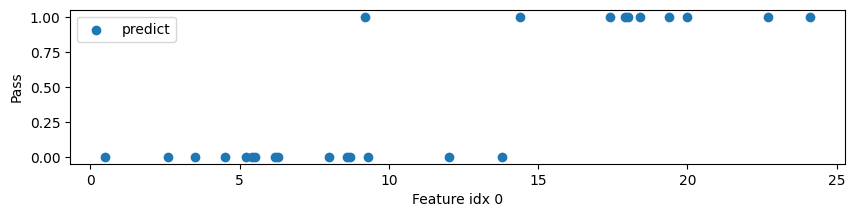

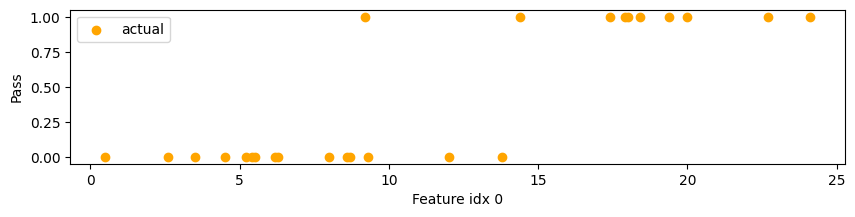

In [23]:
# Visualize the most important feature with the final exam score on the dataset
fig, ax = plt.subplots(figsize=(10,2))
ax.scatter(X[:,f_imp_idx], y_preds, label='predict')
ax.set_xlabel(f'Feature idx {f_imp_idx}')
ax.set_ylabel('Pass')
plt.legend()
plt.show(); plt.close('all');

# Visualize the most important feature with the final exam score on the dataset
fig, ax = plt.subplots(figsize=(10,2))
ax.scatter(X[:,f_imp_idx], y, c='orange', label='actual')
ax.set_xlabel(f'Feature idx {f_imp_idx}')
ax.set_ylabel('Pass')
plt.legend()
plt.show(); plt.close('all');

In [24]:
# Create a new student with quiz=3, lab=4 and midterm=5
X_new = np.array([[3, 4, 5]])


In [25]:
# Predict whether the student will pass the course using the trained logistic regression above
y_hat = model.predict(X_new)
print(y_hat)


[0]


In [26]:
# Performance metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [27]:
acc = accuracy_score(y, y_preds)
prec = precision_score(y, y_preds)
reca = recall_score(y, y_preds)
f1 = f1_score(y, y_preds)
report = classification_report(y, y_preds)

print(f'Accuracy = {acc}')  # higher is better
print(f'Precision = {prec}')  # higher is better
print(f'Recall = {reca}')  # higher is better
print(f'F1 = {f1}')  # higher is better
print(report)

Accuracy = 1.0
Precision = 1.0
Recall = 1.0
F1 = 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      1.00      1.00        10

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



# Tree-based Learning: Predict Outstanding/Satisfactory/Unsatisfactory

Next create a new column, named `Level` where:

* `2`: `(70, 100]`  (i.e., outstanding)
* `1`: `(40, 70]`  (i.e., satisfactory)
* `0`: `(0, 40]` (i.e., unsatisfactory)

In [28]:
score_df['Level'] = pd.cut(score_df['Total'], bins=[0, 40, 70, 100], labels=[0, 1, 2]).astype(int)


Extract `X` and `y`:
* `X`: Quiz, Lab and Midterm
* `y`: Level

Note: Once you select the columns, please use `.values` to extract the data as numpy array.

In [29]:
X = score_df[['Quiz', 'Lab', 'Midterm']].values
y = score_df['Level'].values


In [30]:
print(X)
print(y)

# Expected output:
# [[18.  14.7 15. ]
#  [ 4.5 14.6  3.4]
#  [ 8.7 14.1  4.1]
#  [ 3.5 15.  12.8]
#  [12.  13.7 13.4]
#  [20.  14.4 18.1]
#  [ 8.   6.4  8.4]
#  [ 5.5 14.8  4.4]
#  [ 2.6  6.5  1.3]
#  [ 9.3 13.3  5.3]
#  [ 9.2 14.6 20.3]
#  [17.4 14.3 10.9]
#  [14.4 15.  19.1]
#  [ 5.4 13.2  1.9]
#  [ 0.5  7.2  0. ]
#  [ 6.3 12.5  1.6]
#  [ 6.2 13.2  5.6]
#  [18.4 14.9 17.5]
#  [19.4 15.  20.6]
#  [22.7 14.1 15.9]
#  [24.1 15.  25. ]
#  [ 8.6 12.8 11.6]
#  [17.9 14.8 12.5]
#  [13.8 15.   8.4]
#  [ 5.2 14.3  1.6]]
# [1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 2 2 2 0 1 1 0]

[[18.  14.7 15. ]
 [ 4.5 14.6  3.4]
 [ 8.7 14.1  4.1]
 [ 3.5 15.  12.8]
 [12.  13.7 13.4]
 [20.  14.4 18.1]
 [ 8.   6.4  8.4]
 [ 5.5 14.8  4.4]
 [ 2.6  6.5  1.3]
 [ 9.3 13.3  5.3]
 [ 9.2 14.6 20.3]
 [17.4 14.3 10.9]
 [14.4 15.  19.1]
 [ 5.4 13.2  1.9]
 [ 0.5  7.2  0. ]
 [ 6.3 12.5  1.6]
 [ 6.2 13.2  5.6]
 [18.4 14.9 17.5]
 [19.4 15.  20.6]
 [22.7 14.1 15.9]
 [24.1 15.  25. ]
 [ 8.6 12.8 11.6]
 [17.9 14.8 12.5]
 [13.8 15.   8.4]
 [ 5.2 14.3  1.6]]
[1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 2 2 2 0 1 1 0]


Create and train a decision tree model.

In [31]:
from sklearn.tree import DecisionTreeClassifier

# Create a model
tree = DecisionTreeClassifier(random_state=42)

# Train a model
tree = tree.fit(X, y)


In [32]:
y_preds = tree.predict(X)
print(y_preds)


[1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 2 2 2 0 1 1 0]


In [33]:
acc = accuracy_score(y, y_preds)
prec = precision_score(y, y_preds, average='macro')
reca = recall_score(y, y_preds, average='macro')
f1 = f1_score(y, y_preds, average='macro')
report = classification_report(y, y_preds)

print(f'Accuracy = {acc}')
print(f'Precision = {prec}')
print(f'Recall = {reca}')
print(f'F1 = {f1}')
print(report)

Accuracy = 1.0
Precision = 1.0
Recall = 1.0
F1 = 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00         3

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



Create and train a random forest model.

In [34]:
# Do the same thing on RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

# Create and train model
rf = RandomForestClassifier(random_state=42)
rf = rf.fit(X, y)

# Make prediction
y_preds_rf = rf.predict(X)
print(y_preds_rf)

# Performance metrics
acc = accuracy_score(y, y_preds_rf)
prec = precision_score(y, y_preds_rf, average='macro')
reca = recall_score(y, y_preds_rf, average='macro')
f1 = f1_score(y, y_preds_rf, average='macro')
report = classification_report(y, y_preds_rf)

print(f'Accuracy = {acc}')
print(f'Precision = {prec}')
print(f'Recall = {reca}')
print(f'F1 = {f1}')
print(report)


[1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 2 2 2 0 1 1 0]
Accuracy = 1.0
Precision = 1.0
Recall = 1.0
F1 = 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00         3

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



Create and train an eXtreme Gradient Boosting (XGBoost) model.

In [35]:
# Do the same thing on XGBClassifier
from xgboost import XGBClassifier

# Create and train model
xgb = XGBClassifier(random_state=42)
xgb = xgb.fit(X, y)

# Make prediction
y_preds_xgb = xgb.predict(X)
print(y_preds_xgb)

# Performance metrics
acc = accuracy_score(y, y_preds_xgb)
prec = precision_score(y, y_preds_xgb, average='macro')
reca = recall_score(y, y_preds_xgb, average='macro')
f1 = f1_score(y, y_preds_xgb, average='macro')
report = classification_report(y, y_preds_xgb)

print(f'Accuracy = {acc}')
print(f'Precision = {prec}')
print(f'Recall = {reca}')
print(f'F1 = {f1}')
print(report)


[1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 1 2 2 2 0 1 1 0]
Accuracy = 1.0
Precision = 1.0
Recall = 1.0
F1 = 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00         3

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



Which of the tree-based learning algorithm performs best?

ANSWER: On the training set, all three models (Decision Tree, Random Forest, and XGBoost) achieve 100% Accuracy (1.0) and Macro F1 score (1.0).

However, in practical machine learning and generalizability on unseen test data:
- **Random Forest** and **XGBoost** are substantially superior to a single **Decision Tree** because ensemble methods combine predictions from multiple trees to reduce variance and mitigate severe overfitting.
- Between Random Forest and XGBoost, **Random Forest** is exceptionally reliable for small tabular datasets because bagging with bootstrap aggregation prevents individual trees from memorizing noise without requiring delicate hyperparameter tuning. **XGBoost** uses gradient boosting to sequentially minimize loss and typically achieves state-of-the-art predictive performance when tuned. Therefore, both ensemble models are the top performers.


# Utilize the ML model in Data Science

In [36]:
# Create a new student with lab=4, quiz=3 and midterm=5
# Note: feature column order is [Quiz, Lab, Midterm]
X_new = np.array([[3, 4, 5]])

# Predict whether the student will pass the course using the best model above
best_model = rf  # Random Forest Classifier (or xgb)
y_level_hat = best_model.predict(X_new)
print(f'Predicted Level: {y_level_hat[0]}')

# Level 0 = Unsatisfactory (Fail), Level 1 = Satisfactory (Pass), Level 2 = Outstanding (Pass)
if y_level_hat[0] >= 1:
    print('The student is predicted to PASS the course.')
else:
    print('The student is predicted to FAIL the course.')


Predicted Level: 0
The student is predicted to FAIL the course.


In [37]:
# Calculate the minimum score improvement that the student would need on quiz to pass the course
# Starting scores: quiz=3, lab=4, midterm=5. Maximum possible quiz score is 25.
passed = False
for q in range(3, 26):
    pred = best_model.predict([[q, 4, 5]])[0]
    if pred >= 1:
        improvement = q - 3
        print(f'Minimum score improvement needed on quiz to pass the course: {improvement}')
        passed = True
        break

if not passed:
    print('It is not possible to improve quiz score beyond 25. The student has to improve other scores in addition to the quiz to pass the course.')


It is not possible to improve quiz score beyond 25. The student has to improve other scores in addition to the quiz to pass the course.


In [38]:
# Calculate the minimum score improvement that the student would need on midterm to pass the course
# Starting scores: quiz=3, lab=4, midterm=5. Maximum possible midterm score is 25.
passed = False
for m in range(5, 26):
    pred = best_model.predict([[3, 4, m]])[0]
    if pred >= 1:
        improvement = m - 5
        print(f'Minimum score improvement needed on midterm to pass the course: {improvement}')
        passed = True
        break

if not passed:
    print('It is not possible to improve midterm score beyond 25. The student has to improve other scores in addition to the midterm to pass the course.')


It is not possible to improve midterm score beyond 25. The student has to improve other scores in addition to the midterm to pass the course.
